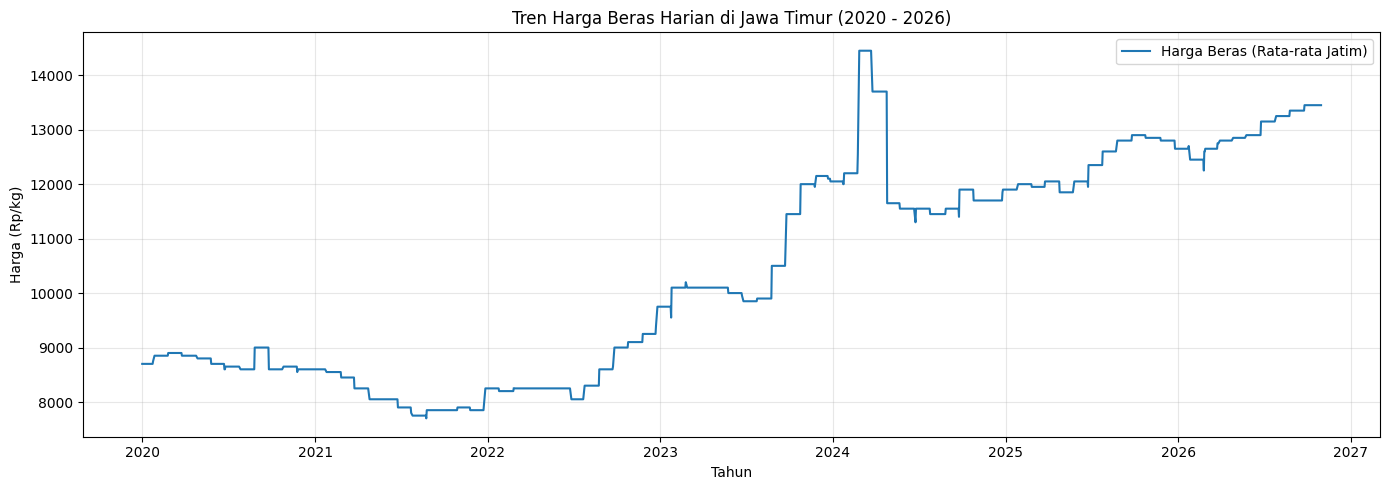

/tmp/ipykernel_1702/2841103808.py:50: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='tahun', y='harga_beras', palette='Blues')


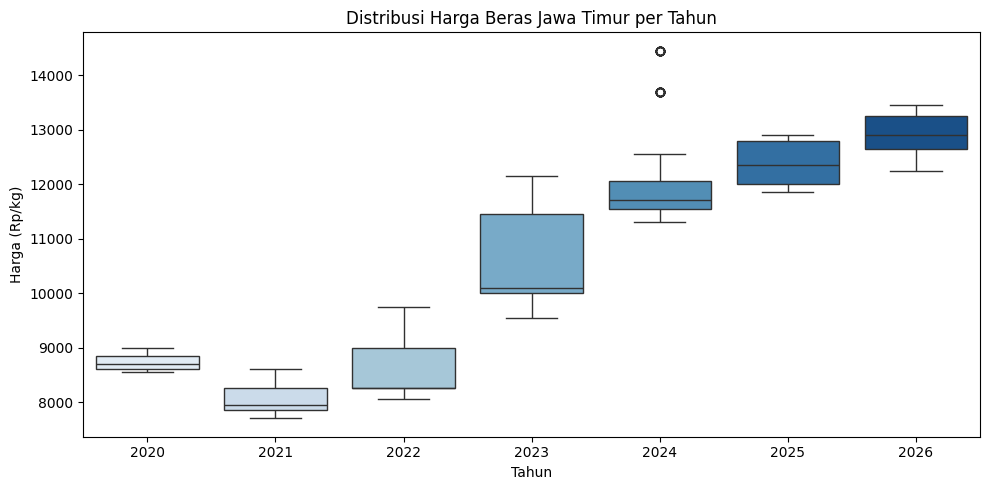

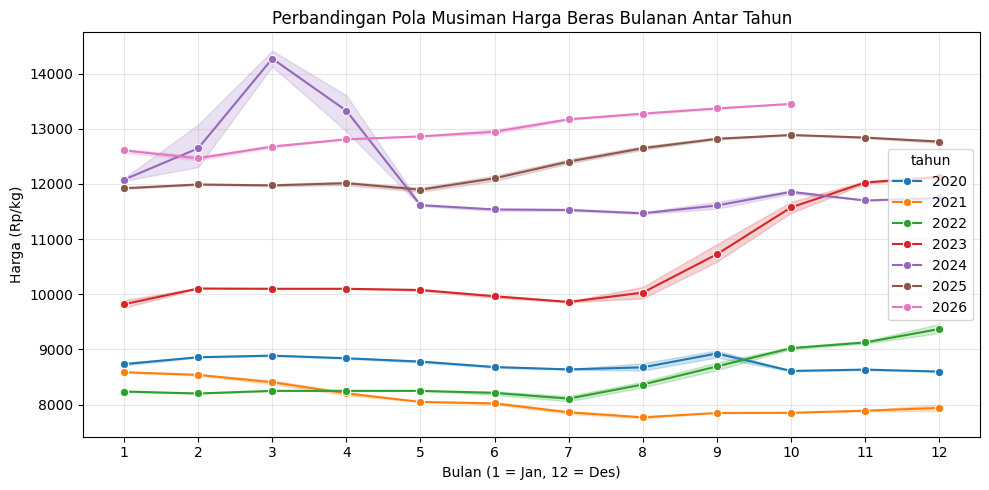

Selesai! 3 gambar grafik tersimpan di folder assets/ pada panel kiri Colab.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Buat folder penyimpanan grafik
os.makedirs('assets', exist_ok=True)

files = ['2020.xlsx', '2021.xlsx', '2022.xlsx', '2023.xlsx', '2024.xlsx', '2025.xlsx', '2026.xlsx']
records = []

for f in files:
    df_raw = pd.read_excel(f, sheet_name='Sheet')
    date_cols = [c for c in df_raw.columns if c not in ['No', 'Komoditas (Rp)']]
    for col in date_cols:
        records.append({
            'tanggal_str': col,
            'beras_raw': df_raw.loc[0, col],
            'beras_med1_raw': df_raw.loc[1, col]
        })

df = pd.DataFrame(records)
df['tanggal'] = pd.to_datetime(df['tanggal_str'].str.replace(' ', ''), format='%d/%m/%Y')
df = df.sort_values('tanggal').reset_index(drop=True)

def clean_price(x):
    s = str(x).replace(',', '').strip()
    return np.nan if s in ['-', '', 'nan', 'None'] else float(s)

df['harga_beras'] = df['beras_raw'].apply(clean_price)
df['harga_beras_medium1'] = df['beras_med1_raw'].apply(clean_price)
df = df[['tanggal', 'harga_beras', 'harga_beras_medium1']]

# 1. Simpan & Tampilkan Grafik Tren Harian
plt.figure(figsize=(14, 5))
plt.plot(df['tanggal'], df['harga_beras'], label='Harga Beras (Rata-rata Jatim)', color='#1f77b4')
plt.title('Tren Harga Beras Harian di Jawa Timur (2020 - 2026)')
plt.xlabel('Tahun')
plt.ylabel('Harga (Rp/kg)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('assets/eda_1_tren_harian.png', dpi=150)
plt.show()

# 2. Simpan & Tampilkan Boxplot Tahunan
df['tahun'] = df['tanggal'].dt.year
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='tahun', y='harga_beras', palette='Blues')
plt.title('Distribusi Harga Beras Jawa Timur per Tahun')
plt.xlabel('Tahun')
plt.ylabel('Harga (Rp/kg)')
plt.tight_layout()
plt.savefig('assets/eda_2_boxplot_tahunan.png', dpi=150)
plt.show()

# 3. Simpan & Tampilkan Pola Musiman Bulanan
df['bulan'] = df['tanggal'].dt.month
plt.figure(figsize=(10, 5))
sns.lineplot(data=df, x='bulan', y='harga_beras', hue='tahun', marker='o', palette='tab10')
plt.title('Perbandingan Pola Musiman Harga Beras Bulanan Antar Tahun')
plt.xlabel('Bulan (1 = Jan, 12 = Des)')
plt.ylabel('Harga (Rp/kg)')
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('assets/eda_3_pola_musiman_bulanan.png', dpi=150)
plt.show()

print("Selesai! 3 gambar grafik tersimpan di folder assets/ pada panel kiri Colab.")